# Modelos de clasificación para detección temprana de fraude en entidades bancarias
## Notebook 02 — Regresión Logística

Sigue la estructura del código de clase *Ingeniería de variables + Regresión Logística*, a partir de la base de modelamiento construida en el **Notebook 01**:

1. **Metodología 1:** *fit train → predict test* (50% / 50%)
2. **Metodología 2:** *fit test → predict train* (se invierten los papeles) → permite medir la **estabilidad**
3. **Entrenamiento completo sin balanceo** de clases
4. **Entrenamiento completo con balanceo** (SMOTE + undersampling)
5. **Predicciones para Kaggle** (archivo csv)


La **regresión logística** modela la probabilidad de fraude mediante la función logit:

$$\log\left(\frac{\theta_i}{1-\theta_i}\right) = \beta_0 + \sum_{j=1}^{p}\beta_j X_{ij}, \qquad \theta_i = P(\text{Fraude}_i = 1 \mid X_i)$$

El hiperparámetro **`C`** es el inverso de la fuerza de regularización (penalización $L_2$, como en Ridge): un `C` pequeño penaliza más los coeficientes.

> **Nota sobre la grilla:** el código de clase prueba `C` de 0.1 a 10 en pasos de 0.1 (100 modelos). Con 848 mil registros la regularización casi no cambia el resultado, así que se usa una grilla de 7 valores en escala amplia (0.01 a 10), que cubre el mismo rango con mucho menor tiempo de cómputo.


### Ajustes técnicos respecto al código de clase (y por qué)
| Código de clase | Este notebook | Motivo |
|---|---|---|
| `make_scorer(roc_auc_score)` y `predict()` (0/1) | `scoring="roc_auc"` y `predict_proba()` | La AUC mide qué tan bien el modelo **ordena** a los clientes por riesgo; con 0/1 la curva ROC tiene un solo punto y la AUC cae fuertemente (se demuestra abajo). Kaggle evalúa la AUC, así que se suben **probabilidades**. |
| `MinMaxScaler().fit_transform(X_test)` | Escalado dentro de un `Pipeline` | El escalado se aprende **solo con entrenamiento** y se aplica igual a test (evita fuga de información). |
| Balanceo de toda la base antes del `GridSearchCV` | Balanceo **dentro** del `Pipeline` | Así los folds de validación conservan la proporción real de fraude (6%) y la AUC de validación no se infla con datos sintéticos. |

## 0. Librerías y configuración

In [1]:
import os, sys, json, time, pickle
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.linear_model import LogisticRegression

SEMILLA = 20042021

In [2]:
if "google.colab" in sys.modules:
    DATA_DIR, ART_DIR = "/content/data/", "/content/artefactos/"
elif "DATABRICKS_RUNTIME_VERSION" in os.environ:
    DATA_DIR, ART_DIR = "/Volumes/main/default/fraude/", "/Volumes/main/default/fraude/artefactos/"
else:
    # Docker / local: busca la carpeta data/ (con train.csv) aquí o en las carpetas de arriba
    carpeta = os.path.abspath(".")
    while not os.path.exists(os.path.join(carpeta, "data", "train.csv")) and carpeta != os.path.dirname(carpeta):
        carpeta = os.path.dirname(carpeta)
    DATA_DIR = os.path.join(carpeta, "data", "")
    ART_DIR = "./artefactos/"
SUB_DIR = "./submissions/"
os.makedirs(ART_DIR, exist_ok=True)
os.makedirs(SUB_DIR, exist_ok=True)
DATA_DIR

'/work/s2/metodos_supervisados/data/'

## 1. Base de modelamiento (Notebook 01)

In [3]:
base_modelo = pd.read_parquet(ART_DIR + "base_modelo_train.parquet")
base_modelo_prueba = pd.read_parquet(ART_DIR + "base_modelo_test.parquet")

covariables = [x for x in base_modelo.columns if x not in ["Fraude"]]
X = base_modelo.get(covariables).copy()
y = base_modelo["Fraude"].copy()
X_prueba = base_modelo_prueba.get(covariables).copy()

print("Entrenamiento:", X.shape, "| Test Kaggle:", X_prueba.shape)
print(f"Tasa de fraude: {100*y.mean():.2f}%")
print("Covariables:", covariables)

Entrenamiento: (848548, 22) | Test Kaggle: (200027, 22)
Tasa de fraude: 5.99%
Covariables: ['Num_Tarjetas', 'Balance_Tj', 'Total_Transac', 'Trans_Int', 'Estado_LB', 'Genero_LB', 'Tipo_Tarjeta_LB', 'Balance_Tj_2', 'Total_Transac_2', 'Num_Tarjetas_2', 'Num_Tarjetas_Balance_Tj', 'Num_Tarjetas_Total_Transac', 'Balance_Tj_Total_Transac', 'Num_Tarjetas_coc_Balance_Tj', 'Balance_Tj_coc_Num_Tarjetas', 'Total_Transac_coc_Num_Tarjetas', 'Genero_Tipo_Tarjeta=Female_Visa', 'Genero_Tipo_Tarjeta=Male_MasterCard', 'Genero_Tipo_Tarjeta=Female_Discover', 'Balance_Tj_x_Genero=Male', 'Num_Tarjetas_x_Genero=Male', 'Balance_Tj_x_Tipo_Tarjeta=MasterCard']


## 2. Funciones de apoyo

In [4]:
N_JOBS = 4   # procesos en paralelo; con -1 (todos los núcleos) Docker se queda sin memoria al usar SMOTE

def crear_modelo(balanceo=False):
    # Pipeline: escalado MinMax (como en clase) -> [balanceo] -> modelo
    pasos = [("escalado", MinMaxScaler())]
    if balanceo:
        # Mismo esquema de clase: SMOTE sobre la clase minoritaria + undersampling de la mayoritaria
        pasos += [("over", SMOTE(sampling_strategy="not majority", random_state=SEMILLA)),
                  ("under", RandomUnderSampler(sampling_strategy="not minority", replacement=True, random_state=SEMILLA))]
    pasos += [("modelo", LogisticRegression(max_iter=2000))]
    return ImbPipeline(pasos) if balanceo else Pipeline(pasos)

parametros = {'modelo__C': [0.01, 0.1, 0.5, 1, 2.5, 5, 10]}

def grilla_auc(X_fit, y_fit, balanceo=False, k=5):
    grilla = GridSearchCV(estimator=crear_modelo(balanceo), param_grid=parametros,
                          scoring="roc_auc", cv=StratifiedKFold(k, shuffle=True, random_state=SEMILLA),
                          n_jobs=N_JOBS, return_train_score=True)
    t0 = time.time()
    grilla.fit(X_fit, y_fit)
    i = grilla.best_index_
    print(f"Mejores hiperparámetros: {grilla.best_params_}  ({time.time()-t0:.0f} s)")
    print(f"AUC validación cruzada ({k} folds): {grilla.cv_results_['mean_test_score'][i]:.4f} ± {grilla.cv_results_['std_test_score'][i]:.4f}")
    return grilla

def umbral_youden(y_true, proba):
    # Umbral que maximiza TPR - FPR (punto de la curva ROC más alejado de la diagonal)
    fpr, tpr, thr = roc_curve(y_true, proba)
    return thr[np.argmax(tpr - fpr)]

def predicciones(modelo, X_eval, y_eval, titulo="", umbral=None):
    proba = modelo.predict_proba(X_eval)[:, 1]
    auc_proba = roc_auc_score(y_eval, proba)
    auc_01 = roc_auc_score(y_eval, (proba >= 0.5).astype(int))
    if umbral is None:
        umbral = umbral_youden(y_eval, proba)
    yhat = (proba >= umbral).astype(int)

    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    sns.heatmap(pd.DataFrame(confusion_matrix(y_eval, yhat)), annot=True, fmt=",.0f", cmap="Blues", ax=ax[0], cbar=False)
    ax[0].set_title(f"Matriz de confusión (umbral = {umbral:.3f})")
    ax[0].set_xlabel("Valores predichos"); ax[0].set_ylabel("Valores observados")
    fpr, tpr, _ = roc_curve(y_eval, proba)
    ax[1].plot(fpr, tpr, color="#C44E52", lw=2, label=f"Probabilidades: AUC = {auc_proba:.4f}")
    fpr2, tpr2, _ = roc_curve(y_eval, (proba >= 0.5).astype(int))
    ax[1].plot(fpr2, tpr2, color="gray", lw=1.5, ls=":", marker="o", label=f"Solo 0/1 (predict): AUC = {auc_01:.4f}")
    ax[1].plot([0, 1], [0, 1], color="lightgray", ls="--")
    ax[1].set_xlabel("FPR (falsas alarmas)"); ax[1].set_ylabel("TPR (recall / sensibilidad)")
    ax[1].set_title("Curva ROC"); ax[1].legend(loc="lower right")
    fig.suptitle(titulo, fontsize=13); plt.tight_layout(); plt.show()

    res = {"AUC": auc_proba, "AUC_0_1": auc_01, "umbral": umbral,
           "Recall": recall_score(y_eval, yhat), "Precision": precision_score(y_eval, yhat), "F1": f1_score(y_eval, yhat)}
    print(f"AUC (probabilidades) = {auc_proba:.4f} | AUC (0/1 con predict) = {auc_01:.4f}")
    print(f"Con umbral {umbral:.3f}: Recall = {res['Recall']:.3f} | Precision = {res['Precision']:.3f} | F1 = {res['F1']:.3f}")
    return res

## 3. Muestras de entrenamiento y test (50% / 50%, estratificado)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=19052023, stratify=y)
print("Train:", X_train.shape, f"fraude {100*y_train.mean():.2f}%")
print("Test: ", X_test.shape, f"fraude {100*y_test.mean():.2f}%")

Train: (424274, 22) fraude 5.99%
Test:  (424274, 22) fraude 5.99%


# Regresión Logística sin balanceo de clases
## Metodología 1: *fit train → predict test*

In [6]:
%%time
grilla1 = grilla_auc(X_train, y_train)

Mejores hiperparámetros: {'modelo__C': 1}  (8 s)
AUC validación cruzada (5 folds): 0.9235 ± 0.0019
CPU times: user 7.13 s, sys: 76.8 ms, total: 7.21 s
Wall time: 8.27 s


### Predicción Train

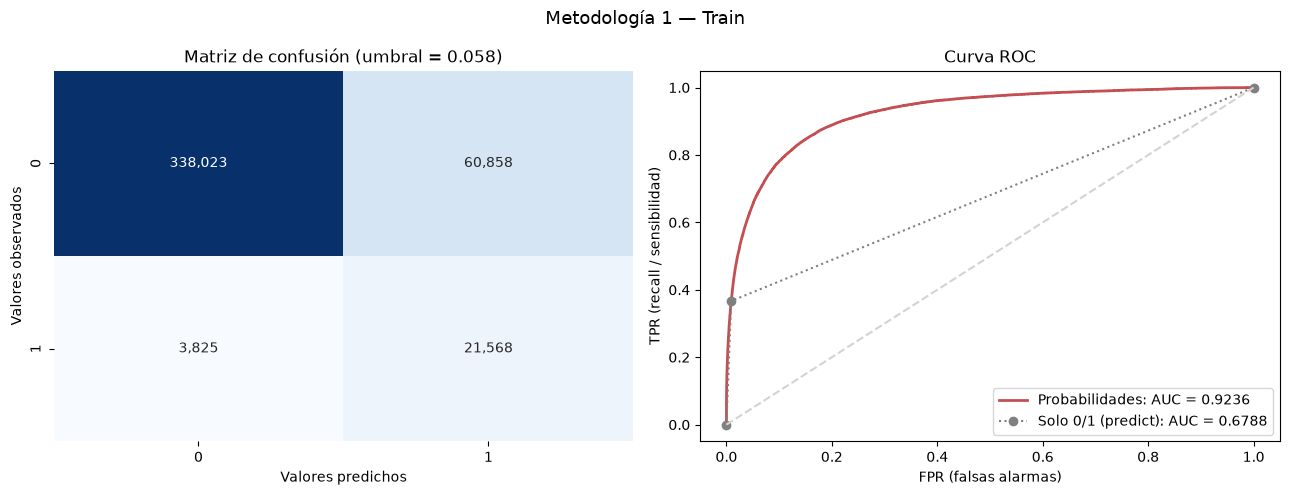

AUC (probabilidades) = 0.9236 | AUC (0/1 con predict) = 0.6788
Con umbral 0.058: Recall = 0.849 | Precision = 0.262 | F1 = 0.400


In [7]:
res1_train = predicciones(grilla1, X_train, y_train, "Metodología 1 — Train")

### Predicción Test

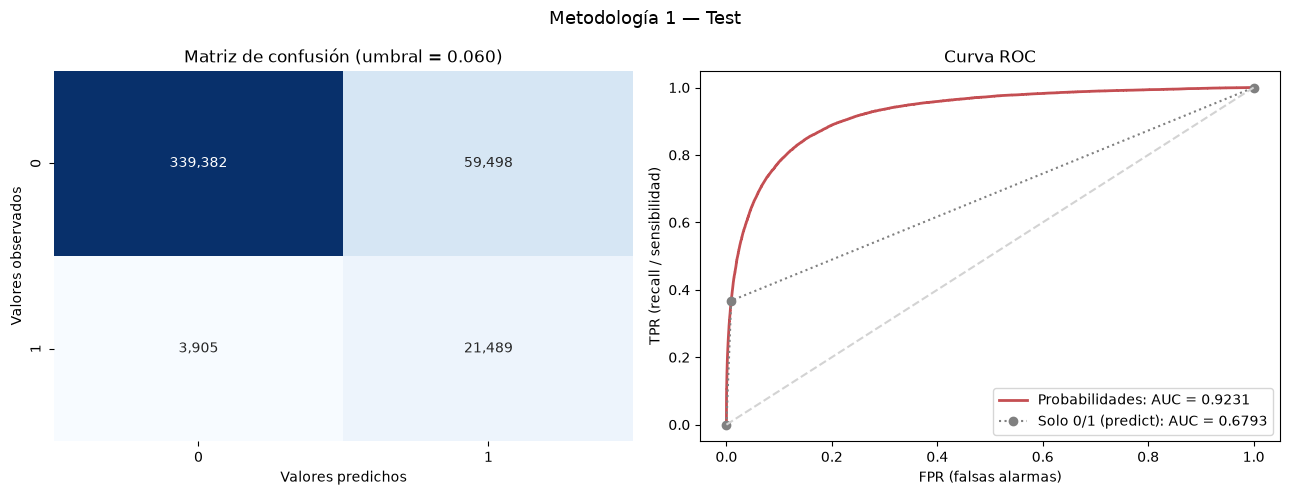

AUC (probabilidades) = 0.9231 | AUC (0/1 con predict) = 0.6793
Con umbral 0.060: Recall = 0.846 | Precision = 0.265 | F1 = 0.404


In [8]:
res1_test = predicciones(grilla1, X_test, y_test, "Metodología 1 — Test")

## Metodología 2: *fit test → predict train*

In [9]:
%%time
grilla2 = grilla_auc(X_test, y_test)

Mejores hiperparámetros: {'modelo__C': 10}  (8 s)
AUC validación cruzada (5 folds): 0.9231 ± 0.0015
CPU times: user 8.24 s, sys: 64 ms, total: 8.3 s
Wall time: 7.62 s


### Predicción Train (la mitad con la que se entrenó: X_test)

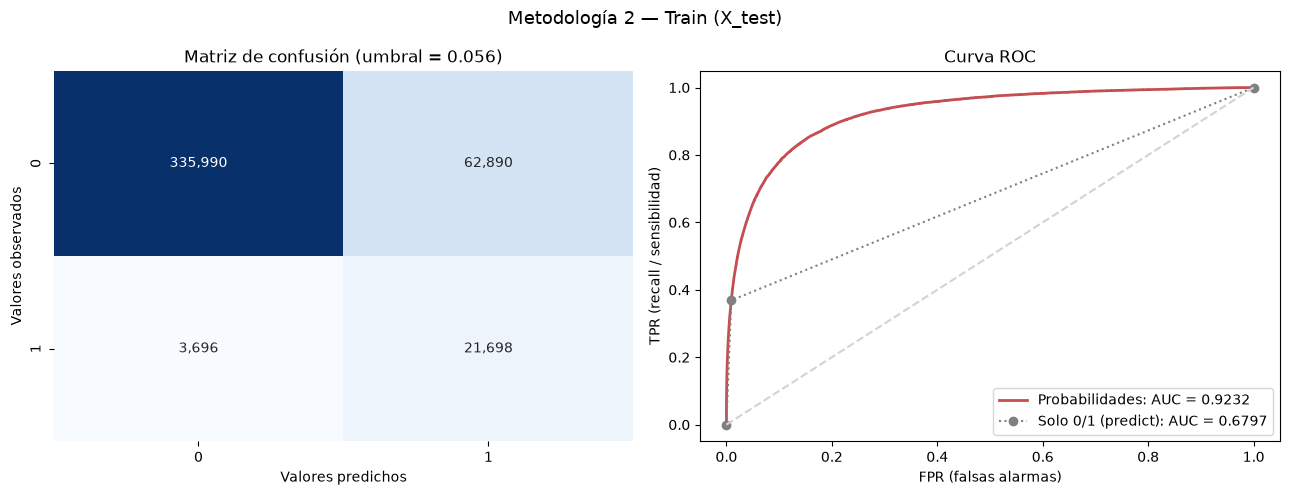

AUC (probabilidades) = 0.9232 | AUC (0/1 con predict) = 0.6797
Con umbral 0.056: Recall = 0.854 | Precision = 0.257 | F1 = 0.395


In [10]:
res2_train = predicciones(grilla2, X_test, y_test, "Metodología 2 — Train (X_test)")

### Predicción Test (la mitad no vista: X_train)

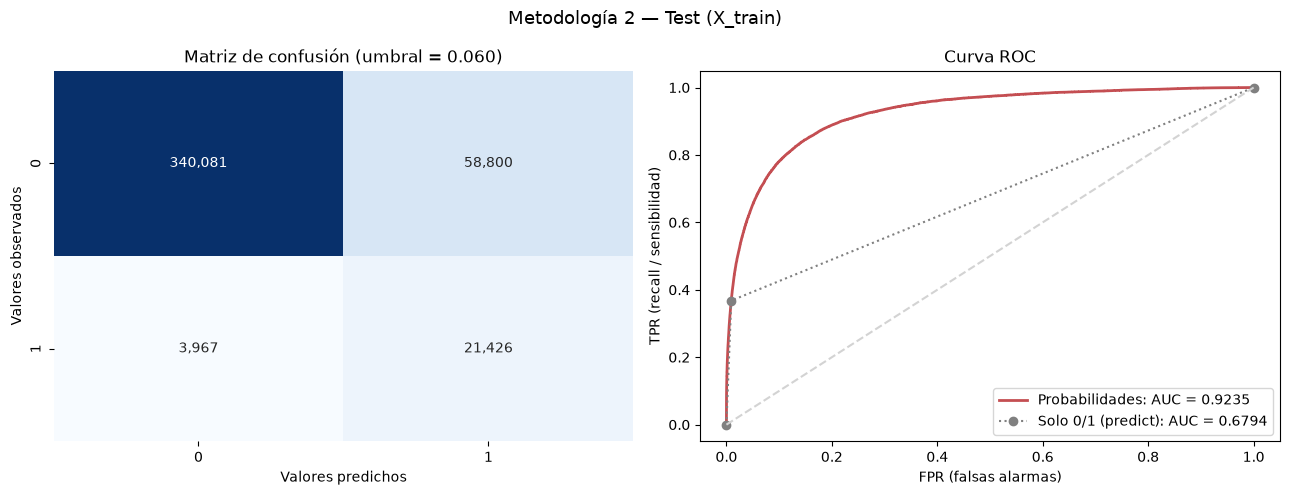

AUC (probabilidades) = 0.9235 | AUC (0/1 con predict) = 0.6794
Con umbral 0.060: Recall = 0.844 | Precision = 0.267 | F1 = 0.406


In [11]:
res2_test = predicciones(grilla2, X_train, y_train, "Metodología 2 — Test (X_train)")

## Estabilidad del modelo
Un modelo **estable** debe tener una AUC similar: (a) entre entrenamiento y prueba (sin sobreajuste), (b) entre las dos metodologías (no depende de qué mitad de los datos se use) y (c) entre los folds de la validación cruzada (desviación estándar pequeña).

In [12]:
def resumen(grilla, r_train, r_test, nombre):
    i = grilla.best_index_
    return {"Metodología": nombre, "Hiperparámetros": str({k.replace("modelo__",""): v for k, v in grilla.best_params_.items()}),
            "AUC CV (media)": grilla.cv_results_["mean_test_score"][i], "AUC CV (desv.)": grilla.cv_results_["std_test_score"][i],
            "AUC Train": r_train["AUC"], "AUC Test": r_test["AUC"], "Brecha Train-Test": r_train["AUC"] - r_test["AUC"],
            "AUC Test con 0/1": r_test["AUC_0_1"]}

estabilidad = pd.DataFrame([resumen(grilla1, res1_train, res1_test, "1: fit train → predict test"),
                            resumen(grilla2, res2_train, res2_test, "2: fit test → predict train")])
estabilidad.round(4)

,Metodología,Hiperparámetros,AUC CV (media),AUC CV (desv.),AUC Train,AUC Test,Brecha Train-Test,AUC Test con 0/1
0,1: fit train → predict test,{'C': 1},0.9235,0.0019,0.9236,0.9231,0.0005,0.6793
1,2: fit test → predict train,{'C': 10},0.9231,0.0015,0.9232,0.9235,-0.0003,0.6794


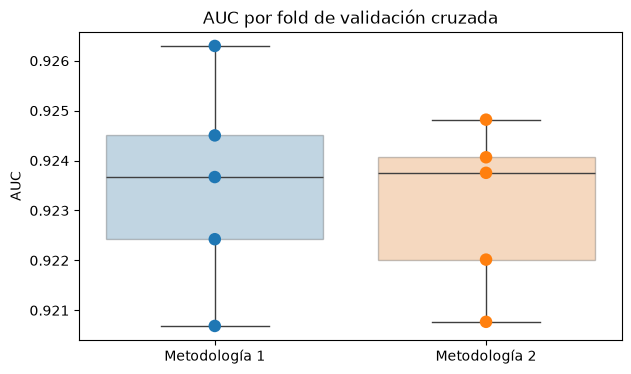

In [13]:
# Distribución de la AUC de validación en los 5 folds para la mejor configuración de cada metodología
folds = pd.DataFrame({f"Metodología {m}": [g.cv_results_[f"split{k}_test_score"][g.best_index_] for k in range(5)]
                      for m, g in [(1, grilla1), (2, grilla2)]})
plt.figure(figsize=(7,4))
sns.stripplot(data=folds, size=9, jitter=False); sns.boxplot(data=folds, boxprops={"alpha":0.3})
plt.title("AUC por fold de validación cruzada"); plt.ylabel("AUC"); plt.show()

# 1. Entrenamiento completo sin balanceo
Se reentrena con **toda** la base de entrenamiento (3 folds, como en clase).

In [14]:
%%time
Random_BE = grilla_auc(X, y, balanceo=False, k=3)

Mejores hiperparámetros: {'modelo__C': 5}  (8 s)
AUC validación cruzada (3 folds): 0.9233 ± 0.0021
CPU times: user 10.6 s, sys: 34.9 ms, total: 10.6 s
Wall time: 7.99 s


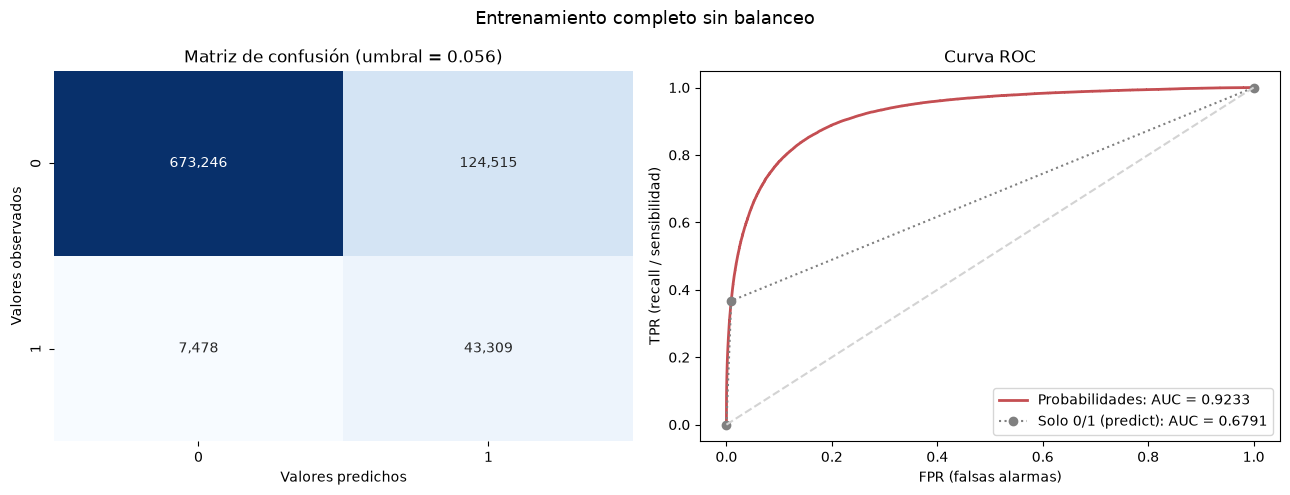

AUC (probabilidades) = 0.9233 | AUC (0/1 con predict) = 0.6791
Con umbral 0.056: Recall = 0.853 | Precision = 0.258 | F1 = 0.396


In [15]:
res_SB = predicciones(Random_BE, X, y, "Entrenamiento completo sin balanceo")

# 2. Entrenamiento completo con balanceo de clases
Se aplica el esquema de clase (`SMOTE` + `RandomUnderSampler`) **dentro de cada fold**. Primero se verifica el efecto del balanceo sobre la proporción de clases:

In [16]:
X_udr, y_udr = ImbPipeline([("over", SMOTE(sampling_strategy="not majority", random_state=SEMILLA)),
                            ("under", RandomUnderSampler(sampling_strategy="not minority", replacement=True, random_state=SEMILLA))]
                          ).fit_resample(MinMaxScaler().fit_transform(X), y)
print(f"Antes:   {X.shape[0]:,} registros | fraude {100*np.mean(y):.2f}%")
print(f"Después: {X_udr.shape[0]:,} registros | fraude {100*np.mean(y_udr):.2f}%")
del X_udr, y_udr

Antes:   848,548 registros | fraude 5.99%
Después: 1,595,522 registros | fraude 50.00%


In [17]:
%%time
Random_BE_Balanced = grilla_auc(X, y, balanceo=True, k=3)

Mejores hiperparámetros: {'modelo__C': 0.5}  (34 s)
AUC validación cruzada (3 folds): 0.9236 ± 0.0022
CPU times: user 36.7 s, sys: 79.2 ms, total: 36.8 s
Wall time: 34.4 s


La evaluación se hace sobre los datos **reales** (sin datos sintéticos):

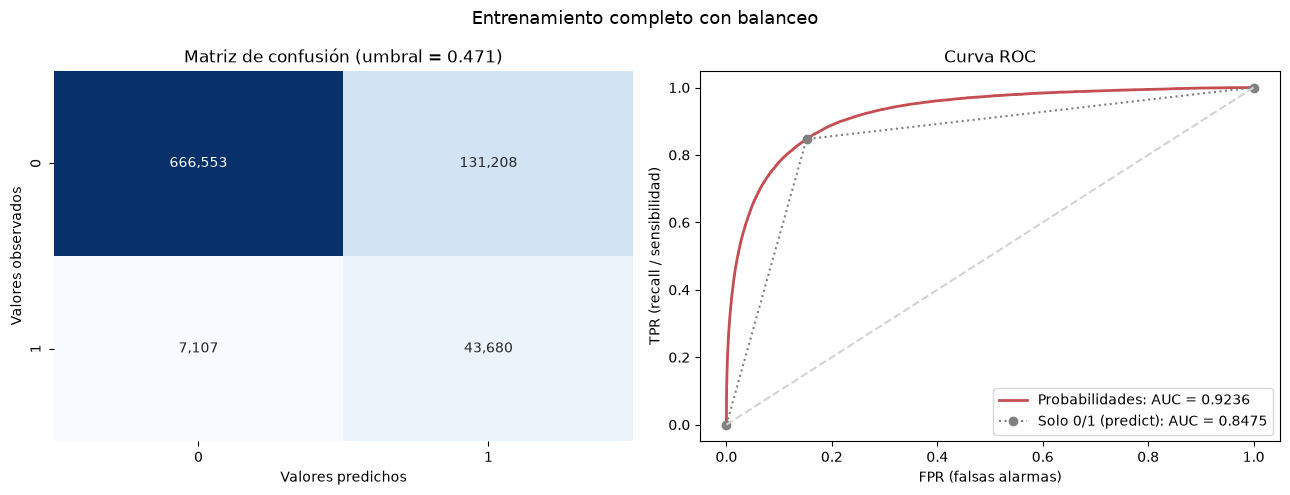

AUC (probabilidades) = 0.9236 | AUC (0/1 con predict) = 0.8475
Con umbral 0.471: Recall = 0.860 | Precision = 0.250 | F1 = 0.387


In [18]:
res_B = predicciones(Random_BE_Balanced, X, y, "Entrenamiento completo con balanceo")

## Comparación: sin balanceo vs con balanceo

In [19]:
comparacion = pd.DataFrame([
    {"Modelo": "Sin balanceo", "AUC CV (media)": Random_BE.best_score_, "AUC CV (desv.)": Random_BE.cv_results_["std_test_score"][Random_BE.best_index_], **{k: v for k, v in res_SB.items()}},
    {"Modelo": "Con balanceo", "AUC CV (media)": Random_BE_Balanced.best_score_, "AUC CV (desv.)": Random_BE_Balanced.cv_results_["std_test_score"][Random_BE_Balanced.best_index_], **{k: v for k, v in res_B.items()}},
]).set_index("Modelo")
comparacion.round(4)

,AUC CV (media),AUC CV (desv.),AUC,AUC_0_1,umbral,Recall,Precision,F1
Modelo,,,,,,,,
Sin balanceo,0.9233,0.0021,0.9233,0.6791,0.0564,0.8528,0.2581,0.3962
Con balanceo,0.9236,0.0022,0.9236,0.8475,0.4715,0.8601,0.2498,0.3871


## Interpretación: coeficientes y odds ratio
Con las variables escaladas entre 0 y 1, cada coeficiente indica cuánto cambia el **logit** del fraude al pasar la variable de su mínimo a su máximo. El **odds ratio** $e^{\beta}$ indica cuántas veces se multiplica la *chance* de fraude.

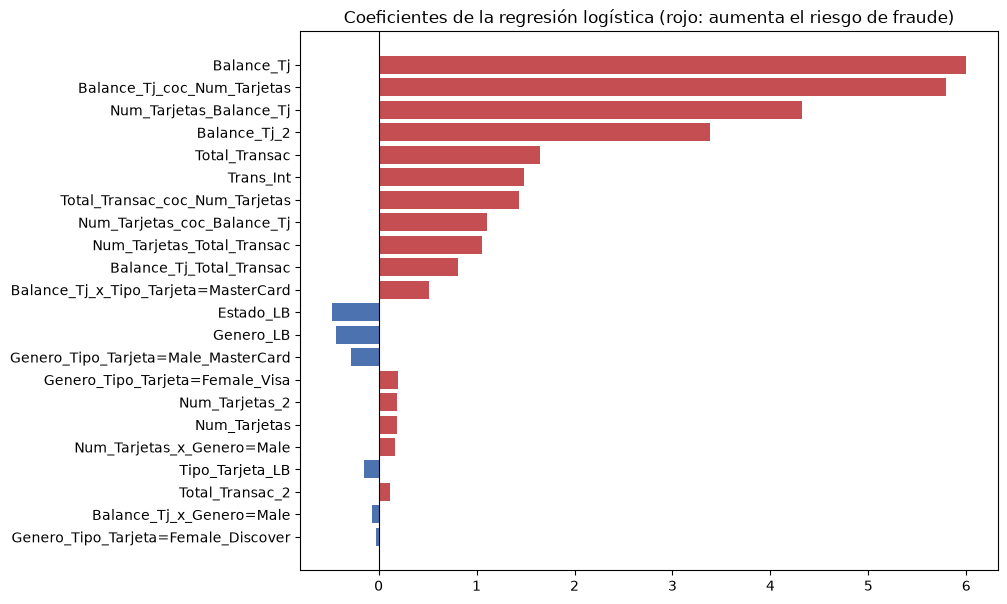

,Variable,Coeficiente,Odds ratio
0,Balance_Tj,5.9998,403.3343
1,Balance_Tj_coc_Num_Tarjetas,5.7971,329.3542
2,Num_Tarjetas_Balance_Tj,4.3253,75.5912
3,Balance_Tj_2,3.3785,29.3265
4,Total_Transac,1.6527,5.2209
5,Trans_Int,1.4799,4.3923
6,Total_Transac_coc_Num_Tarjetas,1.4287,4.1732
7,Num_Tarjetas_coc_Balance_Tj,1.1018,3.0096
8,Num_Tarjetas_Total_Transac,1.0515,2.8618
9,Balance_Tj_Total_Transac,0.8076,2.2425


In [20]:
modelo_final = Random_BE.best_estimator_.named_steps["modelo"]
coefs = pd.DataFrame({"Variable": covariables, "Coeficiente": modelo_final.coef_[0]})
coefs["Odds ratio"] = np.exp(coefs["Coeficiente"])
coefs = coefs.reindex(coefs["Coeficiente"].abs().sort_values(ascending=False).index).reset_index(drop=True)

plt.figure(figsize=(9,7))
plt.barh(coefs["Variable"][::-1], coefs["Coeficiente"][::-1], color=np.where(coefs["Coeficiente"][::-1]>0, "#C44E52", "#4C72B0"))
plt.axvline(0, color="black", lw=0.8); plt.title("Coeficientes de la regresión logística (rojo: aumenta el riesgo de fraude)")
plt.show()
coefs.round(4)

# Análisis de sensibilidad: efecto del orden del `ID`
En el Notebook 01 se encontró que, dentro de cada grupo (Estado, Género, Tipo de tarjeta), el fraude se concentra en los **últimos IDs**. Se construye la variable `pos_ID` = posición relativa (0 a 1) del cliente dentro de su grupo, calculada sobre train y test juntos (los IDs de test están intercalados con los de train), y se mide cuánto cambia la AUC.

> ⚠️ Esta variable es un **artefacto de construcción del archivo** (fuga de información), no un comportamiento del cliente. Se reporta por transparencia y como **riesgo del modelo**; no estaría disponible en un sistema real de prevención de fraude.

In [21]:
grupo = ["Estado", "Genero", "Tipo_Tarjeta"]
crudo = pd.concat([pd.read_csv(DATA_DIR + "train.csv", sep=";", usecols=["ID"] + grupo),
                   pd.read_csv(DATA_DIR + "test.csv",  sep=";", usecols=["ID"] + grupo)])
crudo["pos_ID"] = crudo.groupby(grupo)["ID"].rank(pct=True)
pos = crudo.set_index("ID")["pos_ID"]

ids_train = pd.read_csv(DATA_DIR + "train.csv", sep=";", usecols=["ID"])["ID"]
X_id = X.copy();               X_id["pos_ID"] = pos.loc[ids_train].values
X_prueba_id = X_prueba.copy(); X_prueba_id["pos_ID"] = pos.loc[base_modelo_prueba["ID"]].values

In [22]:
%%time
mejor_balanceo = comparacion["AUC CV (media)"].idxmax() == "Con balanceo"
mejores_params = (Random_BE_Balanced if mejor_balanceo else Random_BE).best_params_
grilla_id = GridSearchCV(crear_modelo(mejor_balanceo), {k: [v] for k, v in mejores_params.items()},
                         scoring="roc_auc", cv=StratifiedKFold(3, shuffle=True, random_state=SEMILLA), n_jobs=N_JOBS).fit(X_id, y)
print(f"AUC CV sin pos_ID: {max(comparacion['AUC CV (media)']):.4f}")
print(f"AUC CV con pos_ID: {grilla_id.best_score_:.4f}")

AUC CV sin pos_ID: 0.9236
AUC CV con pos_ID: 0.9433
CPU times: user 28.6 s, sys: 77 ms, total: 28.7 s
Wall time: 7.45 s


# Predicciones nuevos datos (Kaggle)
Formato del `sample_submission.csv`: columnas `ID` y `Fraude`, separadas por coma. En `Fraude` se sube la **probabilidad** de fraude.

In [23]:
def guardar_submission(proba, nombre):
    evaluacion = pd.DataFrame({"ID": base_modelo_prueba["ID"].values, "Fraude": proba})
    evaluacion.to_csv(SUB_DIR + nombre, index=False, sep=",")
    print(f"{nombre}: {len(evaluacion):,} filas | probabilidad media = {evaluacion['Fraude'].mean():.4f}")
    return evaluacion

sub_SB = guardar_submission(Random_BE.predict_proba(X_prueba)[:, 1],                  "submission_logistica_no_balanceo.csv")
sub_B  = guardar_submission(Random_BE_Balanced.predict_proba(X_prueba)[:, 1],         "submission_logistica_balanceo.csv")
sub_ID = guardar_submission(grilla_id.predict_proba(X_prueba_id)[:, 1],               "submission_logistica_con_posID.csv")
sub_SB.head()

submission_logistica_no_balanceo.csv: 200,027 filas | probabilidad media = 0.0598
submission_logistica_balanceo.csv: 200,027 filas | probabilidad media = 0.2510
submission_logistica_con_posID.csv: 200,027 filas | probabilidad media = 0.2230


,ID,Fraude
0,9,0.011559
1,11,0.002609
2,19,0.003058
3,20,0.005429
4,22,0.001941


In [24]:
# Validación del formato contra la plantilla de Kaggle
plantilla = pd.read_csv(DATA_DIR + "sample_submission.csv")
for s in [sub_SB, sub_B, sub_ID]:
    assert list(s.columns) == list(plantilla.columns) and (s["ID"].values == plantilla["ID"].values).all()
    assert s["Fraude"].between(0, 1).all() and s["Fraude"].notnull().all()
print("✔ Los archivos tienen el mismo formato e IDs que sample_submission.csv")

✔ Los archivos tienen el mismo formato e IDs que sample_submission.csv


## Guardar modelos y resultados (para el Notebook 06 de comparación)

In [25]:
with open(ART_DIR + "modelo_logistica_no_balanceo.pkl", "wb") as f: pickle.dump(Random_BE.best_estimator_, f)
with open(ART_DIR + "modelo_logistica_balanceo.pkl", "wb") as f:    pickle.dump(Random_BE_Balanced.best_estimator_, f)

resultados = {
    "modelo": "Regresión Logística",
    "estabilidad": estabilidad.to_dict(orient="records"),
    "folds_cv": folds.to_dict(orient="list"),
    "completo": comparacion.reset_index().to_dict(orient="records"),
    "auc_cv_con_posID": grilla_id.best_score_,
    "balanceo_elegido": bool(mejor_balanceo),
}
with open(ART_DIR + "resultados_logistica.json", "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2, default=float)
print(sorted(os.listdir(ART_DIR)))

['base_modelo_test.parquet', 'base_modelo_train.parquet', 'modelo_ensamble_balanceo.pkl', 'modelo_ensamble_no_balanceo.pkl', 'modelo_logistica_balanceo.pkl', 'modelo_logistica_no_balanceo.pkl', 'modelo_rforest_balanceo.pkl', 'modelo_rforest_no_balanceo.pkl', 'modelo_xgboost_balanceo.pkl', 'modelo_xgboost_no_balanceo.pkl', 'receta_variables.json', 'resultados_ensamble.json', 'resultados_logistica.json', 'resultados_rforest.json', 'resultados_xgboost.json']


## Conclusiones — Regresión Logística

1. **Desempeño:** AUC ≈ **0.923** en todas las evaluaciones. En la escala de la competencia equivale a una nota de **4.0** (rango 0.901–0.95).
2. **Estabilidad (muy alta):**
   - Brecha train–test de **0.0005** (metodología 1) y **−0.0003** (metodología 2): **no hay sobreajuste**.
   - Las dos metodologías dan prácticamente la misma AUC (0.9231 vs 0.9235): el resultado **no depende** de qué mitad de los datos se use para entrenar.
   - Desviación entre folds de ±0.002.
   - Aunque el `C` óptimo cambia (1, 10, 5, 0.5), la AUC casi no se mueve: con 848 mil registros la regularización tiene poco efecto.
3. **Probabilidades vs 0/1:** con `predict()` (como en el código de clase) la AUC cae a **0.68** sin balanceo (nota 2.0) y a **0.85** con balanceo (nota 2.0–3.0). El balanceo "mejora" el 0/1 solo porque mueve el umbral implícito; **la AUC con probabilidades es la misma con y sin balanceo** (0.9233 vs 0.9236). Por eso a Kaggle se suben **probabilidades**.
4. **Balanceo:** SMOTE + undersampling **no mejora la capacidad de ordenamiento** del modelo y multiplica por 5 el tiempo de entrenamiento (1.6 millones de registros). Su único efecto es recalibrar las probabilidades (la probabilidad media pasa de 6% a 25%).
5. **Decisión de negocio (umbral):** con el umbral óptimo de Youden (≈0.056 sin balanceo), el modelo **detecta el 85% de los fraudes** (recall), pero **solo 1 de cada 4 alertas es un fraude real** (precisión ≈ 0.26). Es el equilibrio entre *detección oportuna* y *falsas alarmas* que plantea el caso. El umbral puede moverse según el costo de cada error para el banco.
6. **Interpretación:** el riesgo de fraude crece sobre todo con el **balance de las tarjetas** (y su relación con el número de tarjetas) y con el **número de transacciones**. Ser hombre (`Genero_LB`) y tener MasterCard reducen el riesgo, coherente con el análisis descriptivo. Los coeficientes de `Num_Tarjetas` y `Num_Tarjetas_2` son idénticos porque la variable solo toma los valores 1 y 2 (al escalar, su cuadrado es la misma columna): hay **redundancia**, que la penalización $L_2$ controla.
7. **Efecto del ID:** agregar la posición del ID (`pos_ID`) sube la AUC de 0.924 a **0.943**. Es fuga de información y se trata como **riesgo** (ver Notebook 01).

**Archivos para Kaggle:** `submissions/submission_logistica_no_balanceo.csv`, `submission_logistica_balanceo.csv` y `submission_logistica_con_posID.csv`.
